In [1]:
import scanpy as sc
import scvelo
import numpy as np
import anndata as ad
import pandas as pd

import warnings
warnings.filterwarnings('ignore')

/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/mnt/volume/Johanna_Velotest/enviroments/velot

In [3]:
print(f"scVelo version: {scvelo.__version__}")
print(f"Scanpy version: {sc.__version__}")

scVelo version: 0.3.3
Scanpy version: 1.9.8


In [4]:
# Dataset 1 - Pancreas
adata_pancreas = scvelo.datasets.pancreas(file_path="../data/original/pancreas.h5ad")
print(adata_pancreas)

# Compute RNA velocity
scvelo.pp.filter_and_normalize(adata_pancreas, min_shared_counts=20, n_top_genes=2000)
scvelo.pp.moments(adata_pancreas, n_pcs=30, n_neighbors=30)

scvelo.tl.recover_dynamics(adata_pancreas, n_jobs=7)
scvelo.tl.velocity(adata_pancreas, mode='dynamical')  
scvelo.tl.velocity_graph(adata_pancreas)
scvelo.tl.velocity_embedding(adata_pancreas)
adata_pancreas.write_h5ad("../data/original/pancreas_dynamical.h5ad")

AnnData object with n_obs × n_vars = 3696 × 27998
    obs: 'clusters_coarse', 'clusters', 'S_score', 'G2M_score'
    var: 'highly_variable_genes'
    uns: 'clusters_coarse_colors', 'clusters_colors', 'day_colors', 'neighbors', 'pca'
    obsm: 'X_pca', 'X_umap'
    layers: 'spliced', 'unspliced'
    obsp: 'distances', 'connectivities'
Filtered out 20801 genes that are detected 20 counts (shared).
Normalized count data: X, spliced, unspliced.
Extracted 2000 highly variable genes.
Logarithmized X.
computing neighbors


/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)
/tmp/ipykernel_870310/2035627425.py:7: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scvelo.pp.moments(adata_pancreas, n_pcs=30, n_neighbors=30)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(


    finished (0:00:10) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 7/28 cores)
or disable the progress bar using `show_progress_bar=False`.


/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/mnt/volume/Johanna_Velotest/enviroments/velot

    finished (0:01:25) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:04) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/28 cores)
    finished (0:00:06) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


In [6]:
# Dataset 2 - Pancreas
adata_pancreas = scvelo.datasets.pancreas(file_path="../data/original/pancreas.h5ad")
print(adata_pancreas)

# Compute RNA velocity
scvelo.pp.filter_and_normalize(adata_pancreas, min_shared_counts=20, n_top_genes=2000)
scvelo.pp.moments(adata_pancreas, n_pcs=30, n_neighbors=30)

scvelo.tl.velocity(adata_pancreas, mode='stochastic')  
scvelo.tl.velocity_graph(adata_pancreas)
scvelo.tl.velocity_embedding(adata_pancreas)
adata_pancreas.write_h5ad("../data/original/pancreas_stochastic.h5ad")

AnnData object with n_obs × n_vars = 3696 × 27998
    obs: 'clusters_coarse', 'clusters', 'S_score', 'G2M_score'
    var: 'highly_variable_genes'
    uns: 'clusters_coarse_colors', 'clusters_colors', 'day_colors', 'neighbors', 'pca'
    obsm: 'X_pca', 'X_umap'
    layers: 'spliced', 'unspliced'
    obsp: 'distances', 'connectivities'
Filtered out 20801 genes that are detected 20 counts (shared).
Normalized count data: X, spliced, unspliced.
Extracted 2000 highly variable genes.
Logarithmized X.
computing neighbors


/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)
/tmp/ipykernel_870310/477826074.py:7: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scvelo.pp.moments(adata_pancreas, n_pcs=30, n_neighbors=30)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(


    finished (0:00:03) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:02) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities


/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/tools/optimization.py:184: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  gamma[i] = np.linalg.pinv(A.T.dot(A)).dot(A.T.dot(y[:, i]))


    finished (0:00:03) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/28 cores)
    finished (0:00:08) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


In [ ]:
# Dataset 3 - dentate gyrus
adata_dentate = scvelo.datasets.dentategyrus(file_path="../data/original/dentategyrus.h5ad")
print(adata_dentate)
scvelo.pp.filter_and_normalize(adata_dentate, min_shared_counts=20, n_top_genes=2000)
scvelo.pp.moments(adata_dentate, n_pcs=30, n_neighbors=30)

# Compute velocity
scvelo.tl.velocity(adata_dentate)
scvelo.tl.velocity_graph(adata_dentate)
scvelo.tl.velocity_embedding(adata_dentate)
adata_dentate.write_h5ad("../data/original/dentategyrus_precomputed.h5ad")

AnnData object with n_obs × n_vars = 2930 × 13913
    obs: 'clusters', 'age(days)', 'clusters_enlarged'
    uns: 'clusters_colors'
    obsm: 'X_umap'
    layers: 'ambiguous', 'spliced', 'unspliced'
Filtered out 10340 genes that are detected 20 counts (shared).
Normalized count data: X, spliced, unspliced.
Extracted 2000 highly variable genes.
Logarithmized X.


/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)
/tmp/ipykernel_852219/3126638997.py:5: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scvelo.pp.moments(adata_dentate, n_pcs=30, n_neighbors=30)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/neighbors.py:233: DeprecationWarning: Automatic computation 

computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/28 cores)


/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/tools/optimization.py:184: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  gamma[i] = np.linalg.pinv(A.T.dot(A)).dot(A.T.dot(y[:, i]))


    finished (0:00:04) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


In [ ]:
# Dataset 4 - gastrulation erythroid
adata_gastrulation = scvelo.datasets.gastrulation_erythroid(file_path="../data/original/gastrulation_erythroid.h5ad")
print(adata_gastrulation)
scvelo.pp.filter_and_normalize(adata_gastrulation, min_shared_counts=20, n_top_genes=2000)
scvelo.pp.moments(adata_gastrulation, n_pcs=30, n_neighbors=30)

# Compute velocity
scvelo.tl.recover_dynamics(adata_gastrulation, n_jobs=8)
scvelo.tl.velocity(adata_gastrulation, mode="dynamical")
scvelo.tl.velocity_graph(adata_gastrulation)
scvelo.tl.velocity_embedding(adata_gastrulation)
adata_gastrulation.write_h5ad("../data/original/gastrulation_erythroid_precomputed.h5ad")

AnnData object with n_obs × n_vars = 9815 × 53801
    obs: 'sample', 'stage', 'sequencing.batch', 'theiler', 'celltype'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'MURK_gene', 'Δm', 'scaled Δm'
    uns: 'celltype_colors'
    obsm: 'X_pca', 'X_umap'
    layers: 'spliced', 'unspliced'
Filtered out 47456 genes that are detected 20 counts (shared).
Normalized count data: X, spliced, unspliced.
Extracted 2000 highly variable genes.
Logarithmized X.
computing neighbors


/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)
/tmp/ipykernel_852219/2527532544.py:5: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scvelo.pp.moments(adata_gastrulation, n_pcs=30, n_neighbors=30)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(


    finished (0:00:18) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:01) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 8/28 cores)


/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/mnt/volume/Johanna_Velotest/enviroments/velot

    finished (0:02:36) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:06) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/28 cores)
    finished (0:00:11) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:01) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


In [ ]:
# Dataset 5 - bone marrow
adata_bonemarrow = scvelo.datasets.bonemarrow(file_path="../data/original/bonemarrow.h5ad")
print(adata_bonemarrow)
scvelo.pp.filter_and_normalize(adata_bonemarrow, min_shared_counts=20, n_top_genes=2000)
scvelo.pp.moments(adata_bonemarrow, n_pcs=30, n_neighbors=30)

# Compute velocity
scvelo.tl.recover_dynamics(adata_bonemarrow, n_jobs=8)
scvelo.tl.velocity(adata_bonemarrow, mode="dynamical")
scvelo.tl.velocity_graph(adata_bonemarrow)
scvelo.tl.velocity_embedding(adata_bonemarrow)
adata_bonemarrow.write_h5ad("../data/original/bonemarrow_precomputed.h5ad")

AnnData object with n_obs × n_vars = 5780 × 14319
    obs: 'clusters', 'palantir_pseudotime'
    uns: 'clusters_colors'
    obsm: 'X_tsne'
    layers: 'spliced', 'unspliced'
Filtered out 7837 genes that are detected 20 counts (shared).
Normalized count data: X, spliced, unspliced.
Extracted 2000 highly variable genes.
Logarithmized X.


/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)
/tmp/ipykernel_852219/4116091324.py:5: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scvelo.pp.moments(adata_bonemarrow, n_pcs=30, n_neighbors=30)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/neighbors.py:233: DeprecationWarning: Automatic computati

computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 8/28 cores)
    finished (0:01:00) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:02) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/28 cores)
    finished (0:00:06) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_tsne', embedded velocity vectors (adata.obsm)


computing velocity graph (using 1/28 cores)
    finished (0:00:07) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


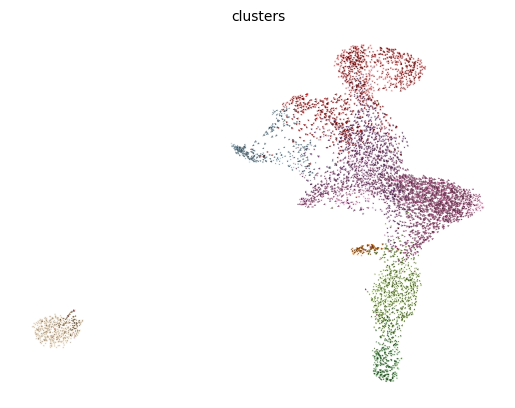

AnnData object with n_obs × n_vars = 5780 × 2000
    obs: 'clusters', 'palantir_pseudotime', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition'
    var: 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes'
    uns: 'clusters_colors', 'log1p', 'neighbors', 'pca', 'recover_dynamics', 'velocity_graph', 'velocity_graph_neg', 'velocity_params', 'umap'
    obsm: 'X_pca', 'X_tsne', 'velocity_tsne', 'X_umap', 'velocity_umap'
    varm: 'PCs', 'loss'
    layers: 'Ms', 'Mu', 'fit_t', 'fit_tau', 'fit_tau_', 'spliced', 'unspliced', 'velocity', 'velocity_u'
    obsp: 'connectivities', 'distances'


In [4]:
adata_bonemarrow = sc.read_h5ad("../data/original/bonemarrow_precomputed.h5ad")
sc.tl.umap(adata_bonemarrow)
scvelo.tl.velocity_graph(adata_bonemarrow)
scvelo.pl.velocity_embedding(adata_bonemarrow, basis='umap')
adata_bonemarrow.write_h5ad("../data/original/bonemarrow_precomputed.h5ad")
print(adata_bonemarrow)

In [ ]:
# Dataset 6 - peripherial blood
adata_pbmc= scvelo.datasets.pbmc68k(file_path="../data/original/pbmc68k.h5ad")
print(adata_pbmc)
adata_pbmc.uns['celltype_color'] = ['#0072b2', '#e69f00', '#d55e00', '#f0e442', '#000000', 
                                      '#56b4e9', '#cc79a7', '#009e73', '#999999', '#4b0082', 
                                      '#fbafe4']
scvelo.pp.filter_and_normalize(adata_pbmc, n_top_genes=3000) # taken from Luo Benchmarking paper
scvelo.pp.moments(adata_pbmc, n_pcs=30, n_neighbors=30)
scvelo.tl.recover_dynamics(adata_pbmc, n_jobs=1)
scvelo.tl.velocity(adata_pbmc, mode='dynamical')
scvelo.tl.velocity_graph(adata_pbmc) 
scvelo.tl.velocity_embedding(adata_pbmc, basis='tsne')
adata_pbmc.write_h5ad("../data/original/pbmc_precomputed.h5ad")

AnnData object with n_obs × n_vars = 65877 × 33939
    obs: 'celltype'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand'
    obsm: 'X_tsne'
    layers: 'spliced', 'unspliced'
Normalized count data: X, spliced, unspliced.
Extracted 3000 highly variable genes.
Logarithmized X.


/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)
/tmp/ipykernel_870310/223107484.py:8: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scvelo.pp.moments(adata_pbmc, n_pcs=30, n_neighbors=30)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/neighbors.py:233: DeprecationWarning: Automatic computation of P

computing neighbors
    finished (0:00:23) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:02) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 1/28 cores)
    finished (0:14:54) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:12) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/28 cores)
    finished (0:00:42) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:16) --> added
    'velocity_tsne', embedded velocity vectors (adata.obsm)


computing velocity graph (using 1/28 cores)
or disable the progress bar using `show_progress_bar=False`.
    finished (0:00:40) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:16) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


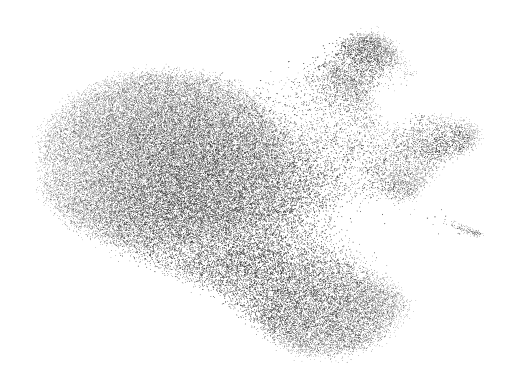

AnnData object with n_obs × n_vars = 65877 × 3000
    obs: 'celltype', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes'
    uns: 'celltype_color', 'log1p', 'neighbors', 'pca', 'recover_dynamics', 'velocity_graph', 'velocity_graph_neg', 'velocity_params', 'umap'
    obsm: 'X_pca', 'X_tsne', 'velocity_tsne', 'X_umap', 'velocity_umap'
    varm: 'PCs', 'loss'
    layers: 'Ms', 'Mu', 'fit_t', 'fit_tau', 'fit_tau_', 'spliced', 'unspliced', 'velocity', 'velocity_u'
    obsp: 'connectivities', 'distances'


In [3]:
adata_pbmc = sc.read_h5ad("../data/original/pbmc_precomputed.h5ad")
sc.tl.umap(adata_pbmc)
scvelo.tl.velocity_graph(adata_pbmc)
scvelo.pl.velocity_embedding(adata_pbmc, basis='umap')
adata_pbmc.write_h5ad("../data/original/pbmc_precomputed.h5ad")
print(adata_pbmc)

AnnData object with n_obs × n_vars = 3076 × 24071
    obs: 'orig.ident', 'clusters', 'cell.type'
    obsm: 'X_umap'
    layers: 'spliced', 'unspliced'
Filtered out 17478 genes that are detected 10 counts (shared).
Normalized count data: X, spliced, unspliced.
Extracted 3000 highly variable genes.


/tmp/ipykernel_940351/3445051564.py:16: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scvelo.pp.moments(adata_covid, n_pcs=30, n_neighbors=20)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/neighbors.py:233: DeprecationWarning: Automatic computation of PCA is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute PCA with Scanpy first.
  _set_pca(adata=adata, n_pcs=n_pcs, use_highly_variable=use_highly_variable)


computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/28 cores)


/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/tools/optimization.py:184: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  gamma[i] = np.linalg.pinv(A.T.dot(A)).dot(A.T.dot(y[:, i]))


    finished (0:00:01) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/plotting/utils.py:68: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  return isinstance(c, str) and c in data.obs.keys() and cat(data.obs[c])
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/plotting/utils.py:68: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  return isinstance(c, str) and c in data.obs.keys() and cat(data.obs[c])


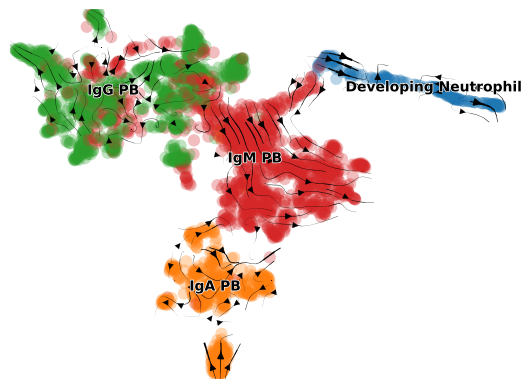

In [8]:
# Dataset 7 - Covid
adata_covid = ad.read_mtx('../data/original/covid/pb1.emat.mtx')  # spliced layer
adata_covid.layers['spliced'] = adata_covid.X
ndata_covid = ad.read_mtx('../data/original/covid/pb1.nmat.mtx')  # unspliced layer
adata_covid.layers['unspliced'] = ndata_covid.X
pd_obs_covid = pd.read_csv('../data/original/covid/pb1.obs.csv')  # annotation of observations
pd_obsm_covid = pd.read_csv('../data/original/covid/pb1.obsm.csv')  # embedding
adata_covid.obs = pd_obs_covid
adata_covid.obsm["X_umap"] = pd_obsm_covid.values
pd_var_names = pd.read_table("../data/original/covid/pb1.var_names.txt", header=None)[0].tolist()  # names of variables
adata_covid.var_names = pd_var_names
print(adata_covid)

# Compute velocity
scvelo.pp.filter_and_normalize(adata_covid, min_shared_counts=10, n_top_genes=3000, log=False)
scvelo.pp.moments(adata_covid, n_pcs=30, n_neighbors=20)

scvelo.tl.velocity(adata_covid, mode='stochastic')
scvelo.tl.velocity_graph(adata_covid)
scvelo.pl.velocity_embedding_stream(adata_covid, basis='umap', color='cell.type', title='', frameon=False, show=False)
adata_covid.write_h5ad("../data/original/covid_precomputed.h5ad")


In [2]:
# Dataset 8 - Retinal development
adata_retina = ad.read_mtx("../data/original/RetinaDevelopment/spliced_count_matrix.mtx.txt")  # spliced layer
adata_retina.layers['spliced'] = adata_retina.X
ndata = ad.read_mtx("../data/original/RetinaDevelopment/unspliced_count_matrix.mtx.txt")  # unspliced layer
adata_retina.layers['unspliced'] = ndata.X
pb_obs = pd.read_csv("../data/original/RetinaDevelopment/metadata.csv") # annotation of observations
adata_retina.obs = pb_obs
pb_obsm = pd.read_csv("../data/original/RetinaDevelopment/embedding.csv") # embedding
adata_retina.obsm['X_umap'] = pb_obsm.values
gene_names = pd.read_csv("../data/original/RetinaDevelopment/genes.csv") # gene names
adata_retina.var_names = gene_names.iloc[:, 0].values
print(adata_retina)

scvelo.pp.filter_and_normalize(adata_retina, min_shared_counts=20, n_top_genes=2000) 
scvelo.pp.moments(adata_retina, n_pcs=30, n_neighbors=30)
scvelo.tl.recover_dynamics(adata_retina, n_jobs=1)
scvelo.tl.velocity(adata_retina, mode='dynamical')
scvelo.tl.velocity_graph(adata_retina) 
scvelo.tl.velocity_embedding(adata_retina, basis='umap')
adata_retina.uns['Annotation_colors'] = ['#0072b2', "#26e600", '#d55e00', '#f0e442', '#000000', '#56b4e9']
adata_retina.write_h5ad("../data/original/retinal_development_precomputed.h5ad")

AnnData object with n_obs × n_vars = 2726 × 31053
    obs: 'CellId', 'Clusters', 'Annotation'
    obsm: 'X_umap'
    layers: 'spliced', 'unspliced'
Filtered out 25381 genes that are detected 20 counts (shared).
Normalized count data: X, spliced, unspliced.
Extracted 2000 highly variable genes.
Logarithmized X.


/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)
/tmp/ipykernel_2585034/4210805008.py:15: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scvelo.pp.moments(adata_retina, n_pcs=30, n_neighbors=30)
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(
/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/neighbors.py:233: DeprecationWarning: Automatic computation

computing neighbors
    finished (0:00:10) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 1/28 cores)
or disable the progress bar using `show_progress_bar=False`.
    finished (0:03:37) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:01) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/28 cores)
    finished (0:00:03) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


In [ ]:
# Dataset 9 - human HSC
adata_hscp = sc.read("../data/original/3423-MV-2_adata_postpro.h5ad")
print(adata_hscp)
scvelo.pp.filter_and_normalize(adata_hscp, n_top_genes=3000)
scvelo.pp.moments(adata_hscp, n_pcs=30, n_neighbors=30)
scvelo.tl.recover_dynamics(adata_hscp, n_jobs=1)
scvelo.tl.velocity(adata_hscp, mode='dynamical')
scvelo.tl.velocity_graph(adata_hscp) 
scvelo.tl.velocity_embedding(adata_hscp, basis='umap')
adata_hscp.write_h5ad("../data/humanHSC_precomputed.h5ad")

AnnData object with n_obs × n_vars = 11605 × 1000
    obs: 'n_counts', 'n_genes_by_counts', 'total_counts', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'S_score', 'G2M_score', 'phase', 'fraction_u', 'leiden', 'root_prediction', 'total_s', 'total_u', 'total_Ms', 'total_Mu'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'mean', 'std'
    uns: 'leiden', 'leiden_colors', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'Ms', 'Mu', 'ambiguous', 'matrix', 'spliced', 'unspliced'
    obsp: 'connectivities', 'distances'
Skip filtering by dispersion since number of variables are less than `n_top_genes`.
Logarithmized X.
computing moments based on connectivities


/mnt/volume/Johanna_Velotest/enviroments/velotest/lib/python3.10/site-packages/scvelo/preprocessing/utils.py:705: DeprecationWarning: `log1p` is deprecated since scVelo v0.3.0 and will be removed in a future version. Please use `log1p` from `scanpy.pp` instead.
  log1p(adata)


    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 1/28 cores)
    finished (0:13:47) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:07) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/28 cores)
    finished (0:00:25) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing velocity embedding
    finished (0:00:02) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)
